# 04 · What drives risk, and which delays are missed?

Use the models fitted on training data in notebook 03. Examine logistic coefficients, measure changes in average precision after shuffling checkout fields, and estimate an ensemble's partial dependence on distance and promise length. Validation orders with outcomes known before the test cutoff supply the out-of-sample evidence for ranking and the fixed-budget error audit.

In [1]:
import json
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.metrics import average_precision_score
from threadpoolctl import threadpool_limits

ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "data/checkout_features.json").is_file())
PROCESSED, RESULTS = ROOT / "data/processed", ROOT / "results"
schema = json.loads((ROOT / "data/checkout_features.json").read_text())
features = sum(schema.values(), [])
decision = json.loads((RESULTS / "model_selection.json").read_text())
fits = joblib.load(PROCESSED / "validation_models.joblib")  # local output of notebook 03
orders = pd.read_parquet(PROCESSED / "orders.parquet")
pred = pd.read_parquet(PROCESSED / "validation_predictions.parquet")
valid = orders.loc[orders.split.eq("validation") & orders.label_observed_at.lt(pd.Timestamp(decision["test_start"]))]
valid = valid.merge(pred, on=["order_id", "late"], how="inner", validate="one_to_one")
assert len(valid) == len(pred) and valid.flagged.sum() == len(valid) // 10
train = orders.loc[orders.split.eq("train") & orders.label_observed_at.lt(pd.Timestamp(decision["validation_start"]))]
with threadpool_limits(limits=2):
    assert np.allclose(fits["selected"].predict_proba(valid[features])[:, 1], valid.risk)
print(f"Validation diagnostics: {len(valid):,} orders, {valid.late.sum():,} delays. "
      f"Selected family: {decision['selected_family']}.")

Validation diagnostics: 12,675 orders, 542 delays. Selected family: Logistic.


## Signs and scale in the regularized logistic model

For a numeric term, a coefficient is the change in log odds for one training standard deviation in the transformed feature. Amounts, counts, package size and distance use log(1 + x) before scaling. For a one-hot categorical field, compare coefficients for two levels of the same field. Correlated predictors can share or exchange importance.

In [2]:
linear = fits["logistic"]
names = linear.named_steps["prepare"].get_feature_names_out()
coef = pd.Series(linear.named_steps["model"].coef_[0], index=names, name="log_odds_coefficient")
coef.rename_axis("transformed_term").to_csv(RESULTS / "logistic_coefficients.csv")
numeric_coef = coef[~coef.index.str.startswith("cat__")].copy()
numeric_coef.index = numeric_coef.index.str.split("__").str[-1]
numeric_coef = numeric_coef.loc[numeric_coef.abs().sort_values(ascending=False).index].to_frame()
numeric_coef["odds_ratio_per_sd"] = np.exp(numeric_coef.log_odds_coefficient)
display(numeric_coef.round(3))
print(f"Regularized family chosen on validation: {decision['regularized_logistic_comparator']}.")

,log_odds_coefficient,odds_ratio_per_sd
promise_days,-0.820,0.440
purchase_month_cos,0.559,1.749
distance_km,0.418,1.519
interstate_item_share,0.251,1.285
freight_brl,0.227,1.255
seller_count,-0.153,0.858
item_count,-0.129,0.879
volume_l,0.060,1.061
max_item_price_brl,0.054,1.055
product_count,-0.040,0.961


Regularized family chosen on validation: Ridge logistic.


## Which checkout information helps ranking?

For each group, shuffle its fields together across the same validation orders and score the previously fitted model again. Shared permutations preserve relationships within a group, including sine–cosine pairs. Loss is measured in AP points. Geography, freight and distance overlap in the information they carry, so the losses need not add up.

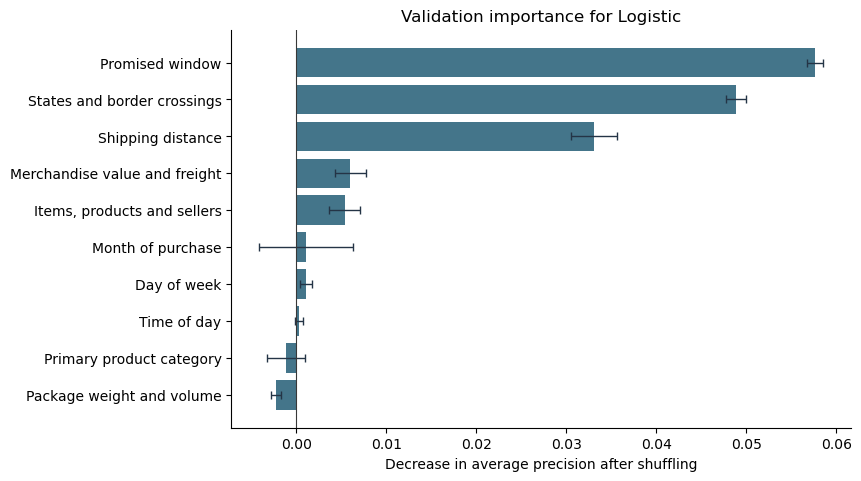

Original validation AP 0.1236. Whiskers show one standard deviation across five shuffles.


In [3]:
groups = {
    "Promised window": ["promise_days"],
    "Shipping distance": ["distance_km"],
    "States and border crossings": ["buyer_state", "primary_seller_state", "interstate_item_share"],
    "Package weight and volume": ["weight_kg", "volume_l"],
    "Merchandise value and freight": ["merchandise_brl", "max_item_price_brl", "freight_brl"],
    "Items, products and sellers": ["item_count", "product_count", "seller_count"],
    "Primary product category": ["primary_category"],
    "Month of purchase": ["purchase_month_sin", "purchase_month_cos"],
    "Time of day": ["purchase_hour_sin", "purchase_hour_cos"],
    "Day of week": ["purchase_weekday"],
}
assert sorted(sum(groups.values(), [])) == sorted(features)
base_ap = average_precision_score(valid.late, valid.risk)
rng = np.random.default_rng(decision["seed"])
permutations = [rng.permutation(len(valid)) for _ in range(5)]
losses = []
with threadpool_limits(limits=2):
    for label, columns in groups.items():
        X = valid[features].copy()
        drops = []
        for permutation in permutations:
            X[columns] = valid[columns].iloc[permutation].to_numpy()
            risk = fits["selected"].predict_proba(X)[:, 1]
            drops.append(base_ap - average_precision_score(valid.late, risk))
        losses.append({"group": label, "mean_ap_drop": np.mean(drops), "shuffle_sd": np.std(drops, ddof=1)})
importance = pd.DataFrame(losses).set_index("group").sort_values("mean_ap_drop")
importance.to_csv(RESULTS / "validation_group_importance.csv")
fig, ax = plt.subplots(figsize=(8.5, 4.7), constrained_layout=True)
ax.barh(importance.index, importance.mean_ap_drop, xerr=importance.shuffle_sd,
        color="#44758a", error_kw={"ecolor": "#243446", "capsize": 3, "elinewidth": 1})
ax.axvline(0, color="#383838", lw=0.8)
ax.set(title=f"Validation importance for {decision['selected_family']}",
       xlabel="Decrease in average precision after shuffling")
ax.spines[["top", "right"]].set_visible(False)
fig.savefig(RESULTS / "validation_group_importance.png", dpi=140)
plt.show()
print(f"Original validation AP {base_ap:.4f}. Whiskers show one standard deviation across five shuffles.")

Shuffling the promised window lowered validation AP by 0.058 on average. Shuffling the states and border crossings together cost 0.049, and distance alone cost 0.033. Shuffling package weight and volume slightly improved AP in this sample, so they offered little evidence of additional ranking value for this fit.

## How does the model combine promise length and distance?

Use the ensemble with the higher validation AP to examine nonlinear responses. At each pair of values, replace the two fields in the same fixed sample of validation baskets and average the predicted probabilities. This is a two-feature partial dependence calculation. Distance levels come from the 15th, 50th and 85th percentiles in training.

The lines connect grid points with at least 50 nearby training orders. Other fields, including buyer and seller states, retain their observed values. Correlation and sparse support limit interpretation as a real change in delivery policy.

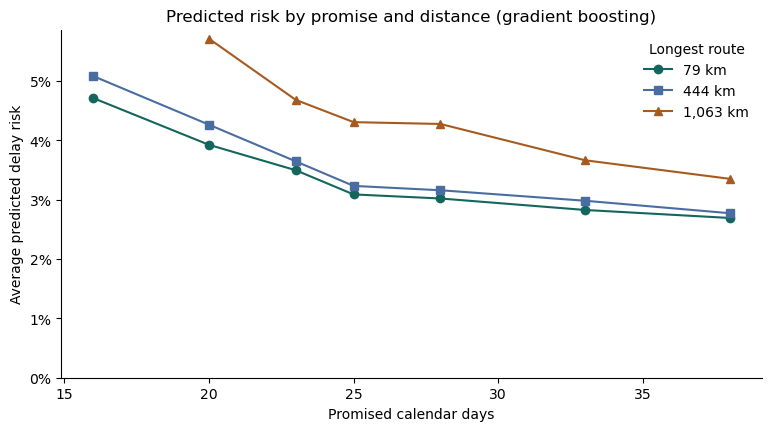

Nearby means within ±2 promised days and ±20% distance (at least ±100 km).


In [4]:
background = valid.sample(n=min(1500, len(valid)), random_state=decision["seed"])[features]
promise_grid = np.unique(np.rint(train.promise_days.quantile([.10, .25, .40, .55, .70, .85, .95])).astype(int))
distance_grid = np.unique(np.rint(train.distance_km.quantile([.15, .50, .85])).astype(int))
points = []
with threadpool_limits(limits=2):
    for km in distance_grid:
        nearby_distance = train.distance_km.sub(km).abs() <= max(100, 0.20 * km)
        for days in promise_grid:
            nearby = nearby_distance & train.promise_days.sub(days).abs().le(2)
            scenario = background.assign(promise_days=days, distance_km=km)
            avg = fits["ensemble"].predict_proba(scenario)[:, 1].mean()
            points.append({"distance_km": km, "promise_days": days, "mean_prediction": avg,
                           "nearby_training_orders": int(nearby.sum())})
surface = pd.DataFrame(points)
surface.to_csv(RESULTS / "validation_partial_dependence.csv", index=False)
fig, ax = plt.subplots(figsize=(7.6, 4.2), constrained_layout=True)
for (km, curve), marker, color in zip(surface.groupby("distance_km"), ["o", "s", "^"],
                                      ["#14665d", "#496da1", "#a75a20"]):
    y = curve.mean_prediction.where(curve.nearby_training_orders >= 50)
    ax.plot(curve.promise_days, y, label=f"{km:,} km", marker=marker, color=color)
ax.yaxis.set_major_formatter(PercentFormatter(1, decimals=0))
ax.set(title=f"Predicted risk by promise and distance ({decision['ensemble_for_interactions'].lower()})",
       xlabel="Promised calendar days", ylabel="Average predicted delay risk", ylim=(0, None))
ax.legend(frameon=False, title="Longest route")
ax.spines[["top", "right"]].set_visible(False)
fig.savefig(RESULTS / "validation_partial_dependence.png", dpi=140)
plt.show()
print("Nearby means within ±2 promised days and ±20% distance (at least ±100 km).")

At a 20-day promise the fitted ensemble averages 3.9% risk for 79 km and 5.7% for 1,063 km. At 38 days the corresponding predictions are 2.7% and 3.4%. The distance gap narrows across these supported combinations in this model.

## Which alerts were false, and which delays were missed?

Keep the single validation-wide alert list from notebook 03. Each group below inherits that decision. Precision and recall use that group's flagged and late orders, respectively. This retains operational differences in the share of orders each group sends for review.

In [5]:
valid["caught"] = valid.flagged & valid.late.eq(1)
valid["false_alert"] = valid.flagged & valid.late.eq(0)
valid["missed"] = ~valid.flagged & valid.late.eq(1)
global_counts = valid[["flagged", "caught", "false_alert", "missed"]].sum().astype(int)
assert global_counts.caught + global_counts.missed == valid.late.sum()
assert global_counts.caught + global_counts.false_alert == valid.flagged.sum()
display(global_counts.rename("validation_orders").to_frame())
by_route = pd.Series(np.select(
    [valid.interstate_item_share.isna(), valid.interstate_item_share.eq(0), valid.interstate_item_share.eq(1)],
    ["Unknown", "Within state", "All interstate"], default="Mixed sellers"), index=valid.index)
by_promise = pd.cut(valid.promise_days, [-np.inf, 14, 21, 30, np.inf],
                    labels=["≤14 days", "15–21 days", "22–30 days", ">30 days"])
by_weight = pd.cut(valid.weight_kg, [-np.inf, 1, 5, 15, np.inf],
                   labels=["≤1 kg", "1–5 kg", "5–15 kg", ">15 kg"])
tables = []
for dimension, labels in {"route": by_route, "promise": by_promise, "package_weight": by_weight}.items():
    group = labels.astype("string").fillna("Unknown").rename("group")
    stats = valid.groupby(group).agg(orders=("late", "size"), late=("late", "sum"),
                                     flagged=("flagged", "sum"), caught=("caught", "sum"),
                                     false_alerts=("false_alert", "sum"), missed=("missed", "sum"))
    stats["recall"] = stats.caught / stats.late.replace(0, np.nan)
    stats["precision"] = stats.caught / stats.flagged.replace(0, np.nan)
    assert stats.orders.sum() == len(valid) and stats.caught.sum() == global_counts.caught
    tables.append(stats.reset_index().assign(dimension=dimension))
errors = pd.concat(tables, ignore_index=True).set_index(["dimension", "group"])
errors.to_csv(RESULTS / "validation_segment_errors.csv")
display(errors.style.format({"recall": "{:.1%}", "precision": "{:.1%}"}, na_rep="—"))

,validation_orders
flagged,1267
caught,187
false_alert,1080
missed,355


The common validation queue captured 180 of 409 delays among wholly interstate orders (44.0%) and 7 of 133 among within-state orders (5.3%). Within-state orders accounted for 126 missed delays. This split identifies a group to examine when the team next develops the ranking model.